# Initial-state experiment: querying at tau=0

Compares four estimates of the true initial state x_0 on the same 8,192 noisy test observation sets, for forced linear, logistic and Stuart–Landau (birth–death is excluded because its initial condition is fixed). All models use M=2^19, training n=128.

1. **Parameter model**: initial-condition coordinates of its parameter estimate.
2. **Prediction model at tau=0**: trajectory prediction with every query time set to 0.
3. **Joint model, parameter output**: initial-condition coordinates of its parameter branch (query tau=0).
4. **Joint model, trajectory output at tau=0**: its trajectory branch at tau=0.

All errors are in **state units normalized by the family state scales**, so the four methods are directly comparable. They are not on the normalized-theta scale used for parameter estimation in notebook 02. No models are loaded and no inference is rerun.
Plots use equal-weight averages across the two trained seeds (errors, not predictions). Test-error bands are within-seed bootstrap intervals for this average, conditional on the trained models, not across-training-seed confidence intervals. Original figure filenames are retained.


In [47]:
from pathlib import Path
import sys

REPO = Path.cwd().resolve()
while not (REPO / "src" / "ode_paper").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
if not (REPO / "src" / "ode_paper").is_dir():
    raise RuntimeError("Run this notebook from inside the Paper repo.")
sys.path.insert(0, str(REPO / "src"))
DOWNLOADS = REPO / "evaluation_cache_downloads"
DOWNLOADS.mkdir(parents=True, exist_ok=True)
print("Repo:", REPO)
print("Place the two downloaded tar.gz files here:", DOWNLOADS)

Repo: <repo>
Place the two downloaded tar.gz files here: <repo>/evaluation_cache_downloads


## Extract the downloaded bundles

On the HPC, `bash hpc/run_initial_state.sh export` writes `initial_state_seed_<seed>.tar.gz` into each seed's results root. Download both into `evaluation_cache_downloads/`. They extract to `seed_<seed>/initial_state_experiment/`, alongside the existing caches.

In [48]:
import tarfile

archives = [DOWNLOADS / f"initial_state_seed_{seed}.tar.gz" for seed in (20260906, 20260907)]
missing = [p for p in archives if not p.is_file()]
if missing:
    print("Still need to download:")
    for path in missing:
        print(" ", path)
else:
    for archive in archives:
        with tarfile.open(archive, "r:gz") as bundle:
            bundle.extractall(DOWNLOADS, filter="data")
        print("Extracted", archive.name)

Extracted initial_state_seed_20260906.tar.gz
Extracted initial_state_seed_20260907.tar.gz


## Load and verify

Each cache folder holds `metrics.json` and `per_example.npz`. The loader checks the array checksum, the cache identity (family, seed, training n, inference n, tau=0, 8,192 examples), that every seed/family/training n has exactly the 9 inference sizes, and that the per-example means reproduce the saved metrics. The per-trajectory all-token MSE averages the saved coordinate MSE over state coordinates; it is not squared again.

In [49]:
import hashlib, json
import numpy as np

SEEDS = (20260906, 20260907)
FAMILIES = ("forced_linear", "logistic", "stuart_landau")
TRAINING_NS = (128,)
EVAL_NS = (2, 4, 8, 16, 32, 64, 128, 256, 512)
METHODS = ("parameter", "prediction", "joint_parameter", "joint_trajectory")

def load_initial_state(directory):
    rows = []
    for seed in SEEDS:
        base = directory / f"seed_{seed}" / "initial_state_experiment"
        for family in FAMILIES:
            for train_n in TRAINING_NS:
                folders = sorted((base / family / f"train_n{train_n}").glob("n*_*"))
                ns = sorted(int(f.name.split("_")[0][1:]) for f in folders)
                if ns != list(EVAL_NS):
                    raise ValueError(f"Missing/duplicate contexts: {family}, train n={train_n}, seed={seed}: {ns}")
                for folder in folders:
                    record = json.loads((folder / "metrics.json").read_text())
                    cache = folder / "per_example.npz"
                    if hashlib.sha256(cache.read_bytes()).hexdigest() != record["array_sha256"]:
                        raise ValueError(f"Checksum mismatch: {cache}")
                    identity = record["identity"]
                    n = int(folder.name.split("_")[0][1:])
                    assert identity["n"] == n and identity["tau"] == 0. and identity["count"] == 8192
                    for task, cfg in identity["configs"].items():
                        assert (cfg["family"], cfg["seed"], cfg["n"], cfg["M"]) == (family, seed, train_n, 2**19), task
                    with np.load(cache, allow_pickle=False) as z:
                        arrays = {k: z[k].copy() for k in z.files}
                    row = dict(seed=seed, family=family, train_n=train_n, inference_n=n,
                               cache=str(folder), arrays=arrays)
                    for method in METHODS:
                        errors = arrays[f"{method}_all_token_coordinate_mse"].astype(float).mean(axis=1)
                        assert len(errors) == 8192 and np.isfinite(errors).all() and (errors >= 0).all()
                        assert np.isclose(errors.mean(), record["metrics"][method]["all_token"], rtol=1e-6)
                        row[f"{method}_errors"] = errors
                    rows.append(row)
    return rows

rows = load_initial_state(DOWNLOADS)
assert len(rows) == len(SEEDS) * len(FAMILIES) * len(TRAINING_NS) * len(EVAL_NS)
print(f"Loaded and verified {len(rows)} evaluations "
      f"({len(rows)//len(SEEDS)} per seed, 4 methods each).")

Loaded and verified 54 evaluations (27 per seed, 4 methods each).


## Plot settings

One 3×1 figure with a panel per family with 8 curves: 4 methods × training n ∈ {128}, averaging the two seed-specific errors. **Color** is the method, with the **dark shade and square markers for training n=128**. All curves are solid and average seeds 20260906 and 20260907 equally. Shading shows pointwise 95% percentile-bootstrap intervals (5,000 resamples of the 8,192 test trajectories), conditional on each trained model, as in notebook 02. Dotted vertical lines mark training n=128.

In [50]:
import matplotlib.pyplot as plt
import importlib
import ode_paper.paper_style as _paper_style
importlib.reload(_paper_style)
from ode_paper.paper_style import apply_style, PAIR_SIZE, SINGLE_SIZE, PANEL_SIZE, context_ticks
apply_style()
plt.rcParams.update({'axes.labelsize': 10, 'axes.titlesize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 8})
from ode_paper.prediction_comparison import bootstrap_mean_ci

BAND_ALPHA = 0.25
LINE_WIDTH = 2.1
MARKER_SIZE = 4
FIGSIZE = (6.4, 2.6)
SAVE_PLOTS = True
SHOW_BANDS = True
SEEDS_TO_PLOT = (20260906, 20260907)
SEED_STYLES = {20260906: "-", 20260907: "--"}
TRAIN_N_MARKERS = {128: "s"}
OUTPUT = REPO / "figures" / "initial_state_experiment" / "notebook_plots"

METHOD_LABELS = {
    "parameter": "Parameter-only transformer output",
    "prediction": r"Prediction-only transformer at $\tau=0$",
    "joint_parameter": "Joint transformer parameter output",
    "joint_trajectory": r"Joint transformer prediction at $\tau=0$",
}
# tab20 pairs: (dark, light) per method; dark = training n=128
_TAB20 = plt.get_cmap("tab20").colors
METHOD_COLORS = {method: {128: _TAB20[2*i], 8: _TAB20[2*i + 1]} for i, method in enumerate(METHODS)}

from ode_paper.seed_average import seed_average
_BOOTSTRAP_INTERVALS = {}

def plot_initial_state(family, family_title, ax=None):
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=FIGSIZE)
    else:
        fig = ax.figure
    curves, positives, upper_values = [], [], []
    for train_n in TRAINING_NS:
        for method in METHODS:
            values=[]
            for n in EVAL_NS:
                errors={};keys=[]
                for seed in (20260906,20260907):
                    matches=[r for r in rows if r['family']==family and r['train_n']==train_n
                             and r['seed']==seed and r['inference_n']==n]
                    if len(matches)!=1: raise ValueError(f'Missing/duplicate cache: {family}, {train_n}, {seed}, {n}')
                    r=matches[0];errors[seed]=r[f'{method}_errors'];keys.append(r['cache'])
                key=(tuple(keys),method,bool(SHOW_BANDS))
                if key not in _BOOTSTRAP_INTERVALS:
                    _BOOTSTRAP_INTERVALS[key]=seed_average(errors,bands=SHOW_BANDS)
                values.append(_BOOTSTRAP_INTERVALS[key])
            mean,lower,upper=np.asarray(values).T
            positives.extend(mean[mean>0]);positives.extend(lower[lower>0]);upper_values.extend(upper)
            curves.append((EVAL_NS,mean,lower,upper,METHOD_COLORS[method][train_n],'--' if train_n==8 else '-',
                           TRAIN_N_MARKERS[train_n],METHOD_LABELS[method] + (f', n={train_n}' if len(TRAINING_NS)>1 else '')))
    assert len(curves)==len(TRAINING_NS)*len(METHODS)

    floor = min(positives)/1.3
    for ns, mean, lower, upper, color, style, marker, label in curves:
        if SHOW_BANDS:
            ax.fill_between(ns, np.where(lower > 0, lower, np.nan), upper,
                            color=color, alpha=BAND_ALPHA, linewidth=0, zorder=1)
        ax.loglog(ns, mean, color=color, linestyle=style, marker=marker,
                  linewidth=LINE_WIDTH, markersize=MARKER_SIZE, label=label, zorder=3)
    for train_n in TRAINING_NS:
        ax.axvline(train_n, color="gray", linestyle=":", linewidth=1, alpha=.65,
                   label="_nolegend_", zorder=2)

    ax.set_ylim(floor, max(max(upper_values)*1.25, floor*2))
    context_ticks(ax, EVAL_NS)
    ax.set(xlabel="Inference observations n",
           ylabel="Normalized MSE",
           title=f'Initial state recovery for {family_title}')
    ax.grid(True, which="both", alpha=.18)
    if standalone:
        ax.legend(loc="upper center", bbox_to_anchor=(.5,-.22), fontsize=8, handlelength=2.0, framealpha=.95, ncol=2)
        fig.tight_layout()
        if SAVE_PLOTS:
            OUTPUT.mkdir(parents=True, exist_ok=True)
            for ext in ("pdf", "png"):
                fig.savefig(OUTPUT/f"{family}_initial_state_tau0.{ext}", dpi=180)
    return fig, ax


GRID_FAMILIES = (("forced_linear", "Forced linear"), ("logistic", "Logistic growth"), ("stuart_landau", "Stuart–Landau"))
GRID_SIZE = (6.4, 7.4)

def plot_initial_state_grid():
    """One 3x1 figure (a panel per family) with a single shared legend below."""
    fig, axes = plt.subplots(len(GRID_FAMILIES), 1, figsize=GRID_SIZE)
    for ax, (family, title) in zip(axes, GRID_FAMILIES):
        plot_initial_state(family, title, ax=ax)
        if ax is not axes[-1]:
            ax.set_xlabel("")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.tight_layout()
    fig.canvas.draw()
    below = axes[-1].get_tightbbox().transformed(fig.transFigure.inverted()).y0  # bottom of x-axis label
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, below - .004), ncol=2,
               fontsize=8, handlelength=1.8, columnspacing=1.0, handletextpad=.5, framealpha=.95)
    if SAVE_PLOTS:
        OUTPUT.mkdir(parents=True, exist_ok=True)
        for ext in ("pdf", "png"):
            fig.savefig(OUTPUT/f"initial_state_tau0.{ext}", dpi=180, bbox_inches="tight")
    return fig, axes

## Combined figure (3×1)

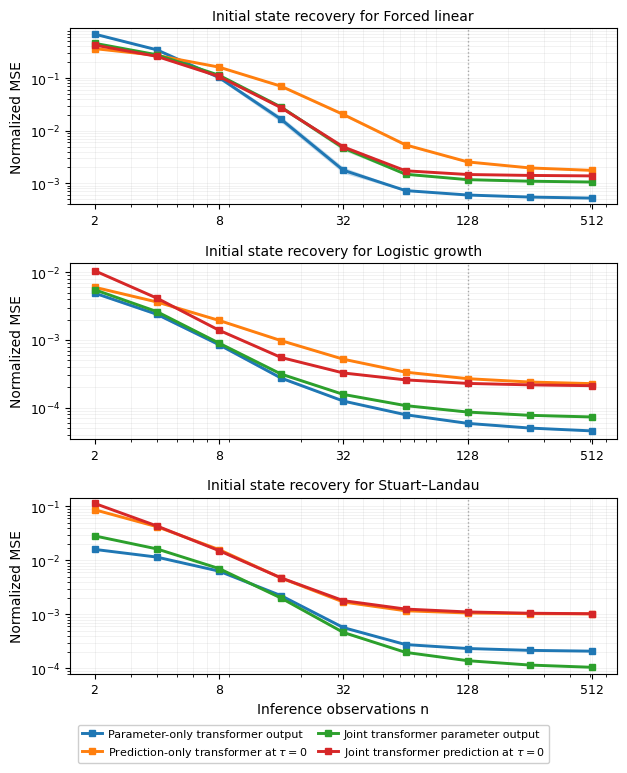

In [51]:
fig, axes = plot_initial_state_grid()
plt.show()